# Trajectory and stationary-law figures

This notebook produces every trajectory- and stationary-law figure in the paper.
All simulations use the scalar pairwise-distance chain
$L_i = \log v_i^2$ from `chain.py`; no external data files.

Figures saved to `figs/`:

- `trajectories_stationary_d100.pdf` &nbsp; (Figure 2)
- `trajectories_above.pdf` &nbsp; (Figure 4)
- `trajectories_below.pdf` &nbsp; (Figure 5)
- `stationary_multidim.pdf` &nbsp; (Figure 6)
- `trajectories_std.pdf` &nbsp; (Figure 7)

Approximate runtime: a few minutes on a single CPU core.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from chain import (
    r_c_of_d, mu_of, jensen_L_star,
    simulate_L_trajectories, simulate_L_long,
)

FIGS = Path("figs")
FIGS.mkdir(exist_ok=True)

DIMS = (1, 10, 100)
LAMS_ABOVE = (1.1, 1.5, 2.5)
LAMS_BELOW_STAT = (0.40, 0.70, 0.94)            # used in stationary_multidim
LAMS_BELOW_TRAJ = (0.30, 0.50, 0.70, 0.85, 0.91, 0.95, 0.97, 0.99, 0.995, 0.999)
N_COPIES_TRAJ = 300
N_STEPS_ABOVE = 200
N_STEPS_BELOW = 2000
BURN_IN_STAT = 20_000
N_KEEP_STAT = 200_000
V1 = 1.0
SEED = 0

## Figure 2 (`trajectories_stationary_d100.pdf`)

Three-pane $d = 100$ summary of the dichotomy from Theorem 4.1: supercritical
trajectories (left), subcritical trajectories (middle), and the stationary law
of $\log v_i^2$ at three subcritical $\lambda$ values (right).

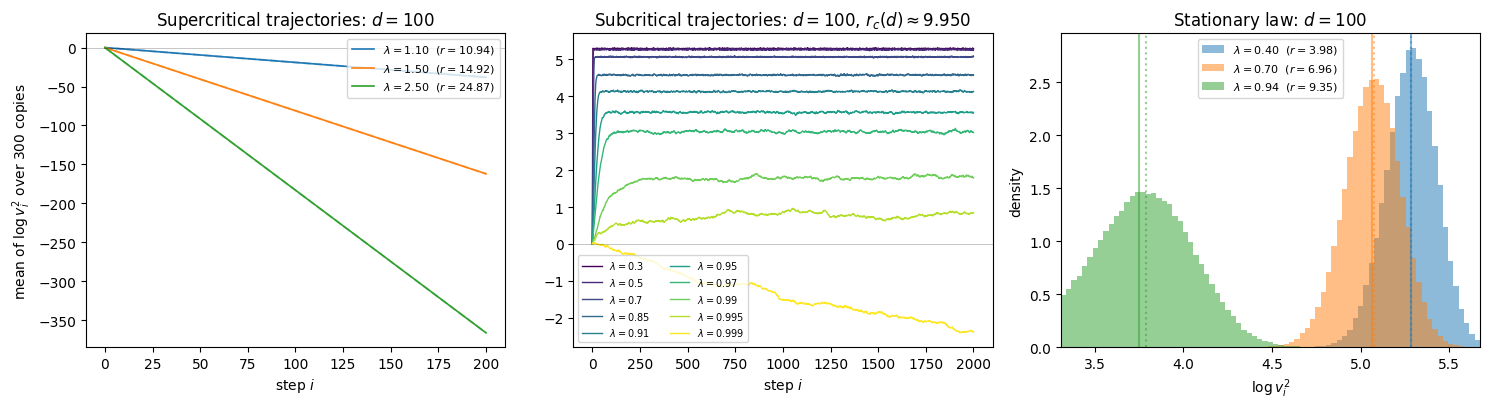

wrote trajectories_stationary_d100.pdf


In [2]:
def make_fig2():
    rng = np.random.default_rng(SEED)
    D = 100
    rc = r_c_of_d(D)
    cmap = plt.get_cmap("viridis")
    colors_traj = [cmap(i / max(len(LAMS_BELOW_TRAJ) - 1, 1))
                   for i in range(len(LAMS_BELOW_TRAJ))]

    fig, (ax_above, ax_traj, ax_stat) = plt.subplots(1, 3, figsize=(15.0, 4.2))

    # Left: supercritical trajectories.
    for lam in LAMS_ABOVE:
        r = lam * rc
        L = simulate_L_trajectories(r, N_STEPS_ABOVE, N_COPIES_TRAJ, V1, rng, d=D)
        mean_L = L.mean(axis=1)
        (line,) = ax_above.plot(mean_L, lw=1.2,
                                label=fr"$\lambda = {lam:.2f}$  ($r = {r:.2f}$)")
        mu = mu_of(D, r)
        ax_above.plot(np.arange(N_STEPS_ABOVE + 1),
                      np.log(V1**2) - mu * np.arange(N_STEPS_ABOVE + 1),
                      "--", color=line.get_color(), alpha=0.4)
    ax_above.set_title(fr"Supercritical trajectories: $d = {D}$")
    ax_above.set_xlabel(r"step $i$")
    ax_above.set_ylabel(r"mean of $\log v_i^2$ over $300$ copies")
    ax_above.axhline(0.0, color="k", lw=0.4, alpha=0.4)
    ax_above.legend(fontsize=8, loc="upper right")

    # Middle: subcritical trajectories.
    for li, lam in enumerate(LAMS_BELOW_TRAJ):
        r = lam * rc
        L = simulate_L_trajectories(r, N_STEPS_BELOW, N_COPIES_TRAJ, V1, rng, d=D)
        ax_traj.plot(L.mean(axis=1), color=colors_traj[li], lw=1.0,
                     label=fr"$\lambda = {lam}$")
    ax_traj.set_title(fr"Subcritical trajectories: $d = {D}$, $r_c(d) \approx {rc:.3f}$")
    ax_traj.set_xlabel(r"step $i$")
    ax_traj.axhline(0.0, color="k", lw=0.4, alpha=0.4)
    ax_traj.legend(fontsize=7, loc="best", ncol=2)

    # Right: stationary law.
    tails = []
    for lam in LAMS_BELOW_STAT:
        r = lam * rc
        L = simulate_L_long(r, BURN_IN_STAT + N_KEEP_STAT, V1, rng, d=D)
        tails.append((lam, r, L[BURN_IN_STAT + 1:]))
    lo = min(np.quantile(t, 0.08) for _, _, t in tails)
    hi = max(np.quantile(t, 0.998) for _, _, t in tails)
    bins = np.linspace(lo, hi, 80)
    for lam, r, L_tail in tails:
        L_in = L_tail[(L_tail >= lo) & (L_tail <= hi)]
        _, _, patches = ax_stat.hist(L_in, bins=bins, density=True, alpha=0.5,
                                     label=fr"$\lambda = {lam:.2f}$  ($r = {r:.2f}$)")
        color = patches[0].get_facecolor()
        ax_stat.axvline(L_tail.mean(), color=color, linestyle="-", linewidth=1.5)
        ax_stat.axvline(jensen_L_star(r, D), color=color, linestyle=":", linewidth=1.5)
    ax_stat.set_xlim(lo, hi)
    ax_stat.set_title(fr"Stationary law: $d = {D}$")
    ax_stat.set_xlabel(r"$\log v_i^2$")
    ax_stat.set_ylabel("density")
    ax_stat.legend(fontsize=8, loc="best")

    fig.tight_layout()
    fig.savefig(FIGS / "trajectories_stationary_d100.pdf", bbox_inches="tight")
    plt.show()
    print("wrote trajectories_stationary_d100.pdf")

make_fig2()

## Figure 4 (`trajectories_above.pdf`)

Supercritical regime $r > r_c(d)$ across $d \in \{1, 10, 100\}$. Mean
$\log v_i^2$ decays linearly at rate $-2\log\lambda$, matched across
dimensions; grey dashed reference line.

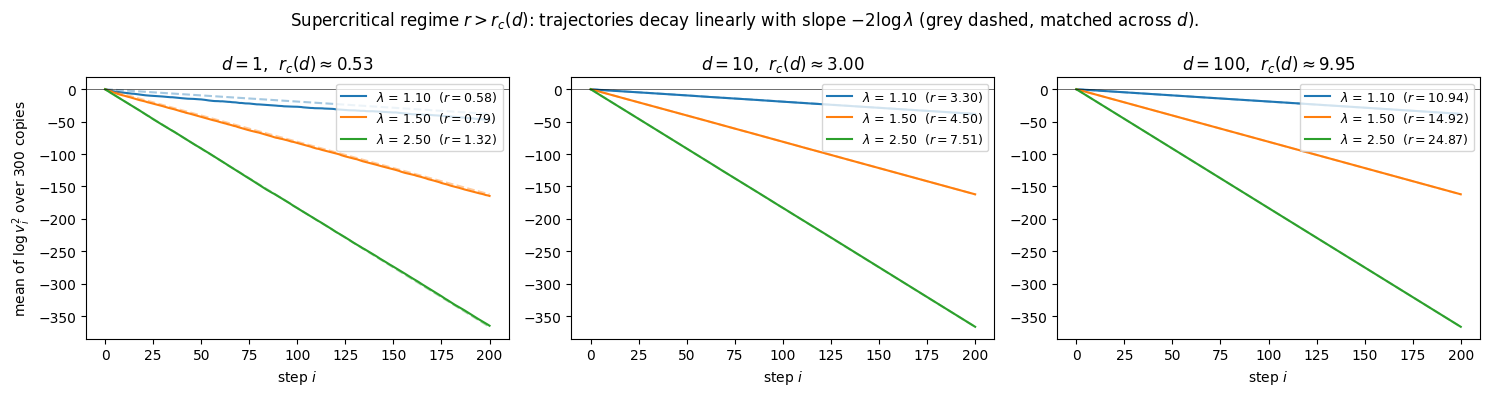

wrote trajectories_above.pdf


In [3]:
def make_fig4():
    rng = np.random.default_rng(SEED)
    n_steps, n_copies = N_STEPS_ABOVE, N_COPIES_TRAJ
    fig, axes = plt.subplots(1, len(DIMS), figsize=(5.0 * len(DIMS), 4.0), sharex=True)
    for ax, d in zip(axes, DIMS):
        rc = r_c_of_d(d)
        for lam in LAMS_ABOVE:
            r = lam * rc
            L = simulate_L_trajectories(r, n_steps, n_copies, V1, rng, d=d)
            (line,) = ax.plot(L.mean(axis=1),
                              label=fr"$\lambda$ = {lam:.2f}  ($r = {r:.2f}$)")
            mu = mu_of(d, r)
            ax.plot(np.arange(n_steps + 1),
                    np.log(V1**2) - mu * np.arange(n_steps + 1),
                    "--", color=line.get_color(), alpha=0.4)
        ax.set_title(fr"$d = {d}$,  $r_c(d) \approx {rc:.2f}$")
        ax.set_xlabel("step $i$")
        ax.axhline(0.0, color="k", lw=0.4)
        ax.legend(loc="upper right", fontsize=9)
    axes[0].set_ylabel(r"mean of $\log v_i^2$ over 300 copies")
    fig.suptitle(r"Supercritical regime $r > r_c(d)$: trajectories decay linearly with"
                 r" slope $-2\log\lambda$ (grey dashed, matched across $d$).")
    fig.tight_layout()
    fig.savefig(FIGS / "trajectories_above.pdf")
    plt.show()
    print("wrote trajectories_above.pdf")

make_fig4()

## Figure 5 (`trajectories_below.pdf`)

Subcritical regime $r < r_c(d)$ across $d \in \{1, 10, 100\}$. Ten
$\lambda$ values from $0.30$ to $0.999$, depth $2000$.

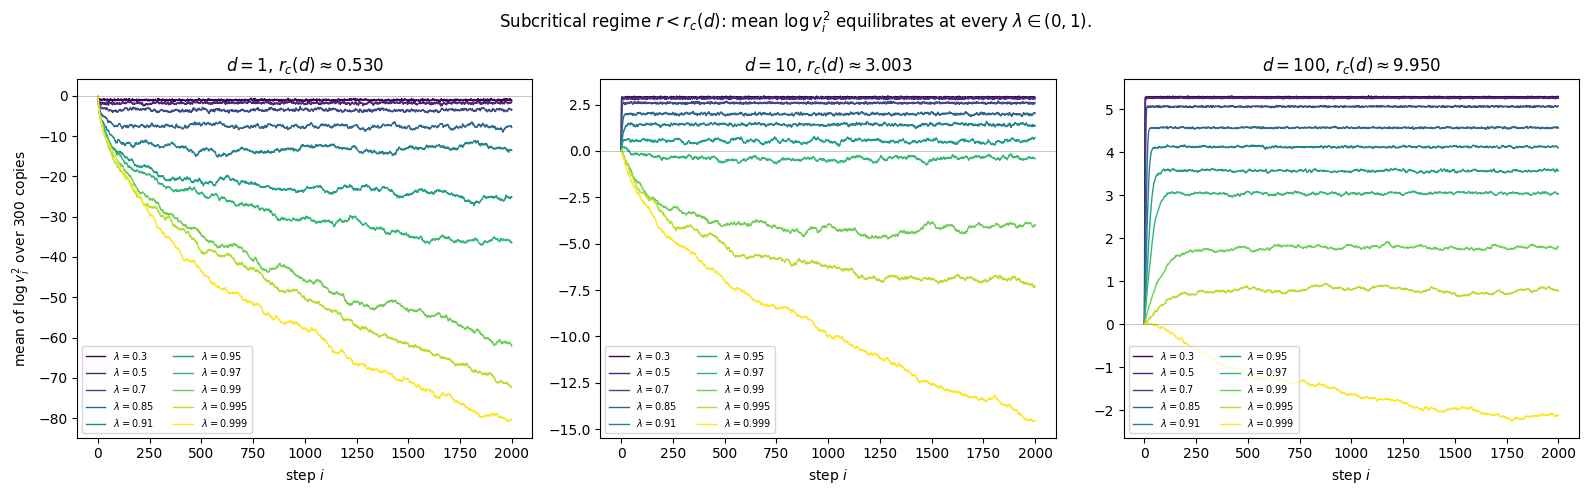

wrote trajectories_below.pdf


In [4]:
def make_fig5():
    rng = np.random.default_rng(SEED)
    n_steps, n_copies = N_STEPS_BELOW, N_COPIES_TRAJ
    cmap = plt.get_cmap("viridis")
    colors = [cmap(i / max(len(LAMS_BELOW_TRAJ) - 1, 1))
              for i in range(len(LAMS_BELOW_TRAJ))]
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax_idx, d in enumerate(DIMS):
        ax = axes[ax_idx]
        rc = r_c_of_d(d)
        for li, lam in enumerate(LAMS_BELOW_TRAJ):
            r = lam * rc
            L = simulate_L_trajectories(r, n_steps, n_copies, V1, rng, d=d)
            ax.plot(L.mean(axis=1), color=colors[li], lw=1.0, label=fr"$\lambda = {lam}$")
        ax.set_title(fr"$d = {d}$, $r_c(d) \approx {rc:.3f}$")
        ax.set_xlabel(r"step $i$")
        ax.axhline(0.0, color="k", lw=0.4, alpha=0.4)
        ax.legend(fontsize=7, loc="best", ncol=2)
    axes[0].set_ylabel(r"mean of $\log v_i^2$ over $300$ copies")
    fig.suptitle(r"Subcritical regime $r < r_c(d)$: mean $\log v_i^2$ equilibrates "
                 r"at every $\lambda \in (0,1)$.")
    fig.tight_layout()
    fig.savefig(FIGS / "trajectories_below.pdf", bbox_inches="tight")
    plt.show()
    print("wrote trajectories_below.pdf")

make_fig5()

## Figure 6 (`stationary_multidim.pdf`)

Empirical stationary law of $\log v_i^2$ at $\lambda \in \{0.40, 0.70, 0.94\}$,
overlaid per dimension ($d = 1, 10, 100$). $2 \cdot 10^5$ samples after
$2 \cdot 10^4$-step burn-in. Solid verticals: empirical mean. Dotted: Jensen
upper bound $L_*(r, d)$.

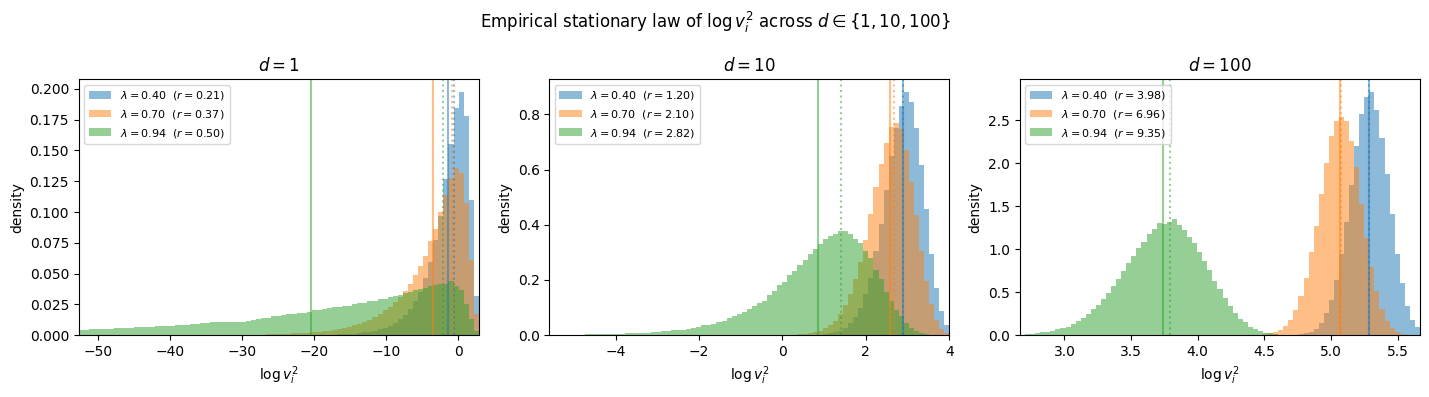

wrote stationary_multidim.pdf


In [5]:
def make_fig6():
    rng = np.random.default_rng(SEED)
    fig, axes = plt.subplots(1, len(DIMS), figsize=(4.8 * len(DIMS), 4.0))
    for ax, d in zip(axes, DIMS):
        rc = r_c_of_d(d)
        tails = []
        for lam in LAMS_BELOW_STAT:
            r = lam * rc
            L = simulate_L_long(r, BURN_IN_STAT + N_KEEP_STAT, V1, rng, d=d)
            tails.append((lam, r, L[BURN_IN_STAT + 1:]))
        lo_q = 0.08 if d == 1 else 0.001
        lo = min(np.quantile(t, lo_q) for _, _, t in tails)
        hi = max(np.quantile(t, 0.998) for _, _, t in tails)
        bins = np.linspace(lo, hi, 80)
        for lam, r, L_tail in tails:
            L_in = L_tail[(L_tail >= lo) & (L_tail <= hi)]
            _, _, patches = ax.hist(L_in, bins=bins, density=True, alpha=0.5,
                                    label=fr"$\lambda = {lam:.2f}$  ($r = {r:.2f}$)")
            color = patches[0].get_facecolor()
            ax.axvline(L_tail.mean(), color=color, linestyle="-", linewidth=1.5)
            ax.axvline(jensen_L_star(r, d), color=color, linestyle=":", linewidth=1.5)
        ax.set_xlim(lo, hi)
        ax.set_title(fr"$d = {d}$")
        ax.set_xlabel(r"$\log v_i^2$")
        ax.set_ylabel("density")
        ax.legend(fontsize=8, loc="best")
    fig.suptitle(r"Empirical stationary law of $\log v_i^2$ across $d \in \{1, 10, 100\}$")
    fig.tight_layout()
    fig.savefig(FIGS / "stationary_multidim.pdf", bbox_inches="tight")
    plt.show()
    print("wrote stationary_multidim.pdf")

make_fig6()

## Figure 7 (`trajectories_std.pdf`)

Sample std of $\log v_i^2$ across the same $300$ i.i.d.\ copies used in Figures 4, 5, vs. depth $i$. Top row: supercritical, depth $200$. Bottom row: subcritical, depth $2000$. The standard error of the mean trajectory estimator is the std displayed here divided by $\sqrt{300}$.

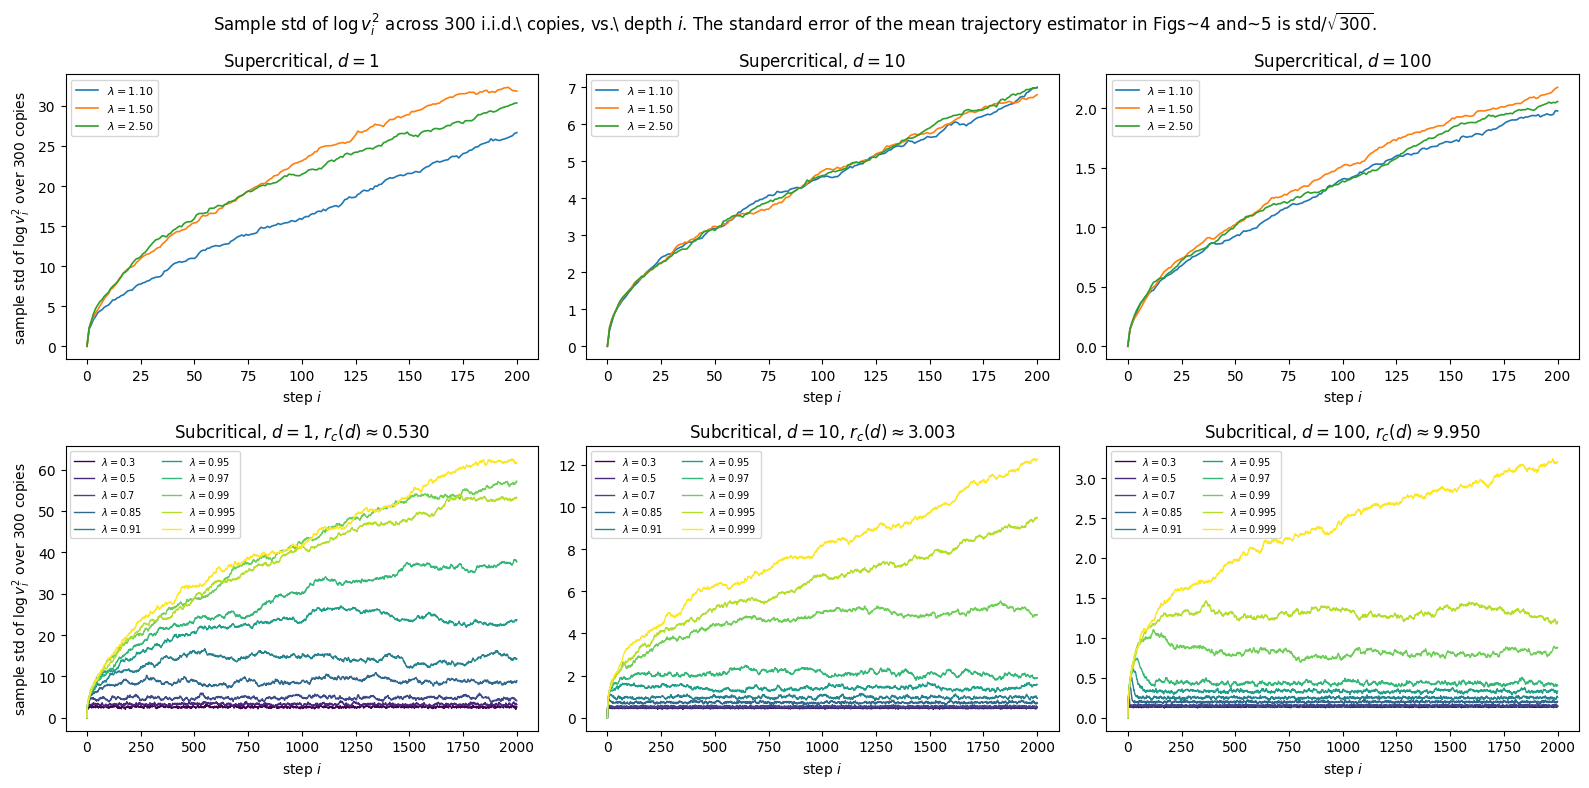

wrote trajectories_std.pdf


In [6]:
def make_fig11():
    rng = np.random.default_rng(SEED)
    cmap = plt.get_cmap("viridis")
    colors_below = [cmap(i / max(len(LAMS_BELOW_TRAJ) - 1, 1))
                    for i in range(len(LAMS_BELOW_TRAJ))]

    fig, axes = plt.subplots(2, 3, figsize=(16, 8), sharex=False)
    for ax_idx, d in enumerate(DIMS):
        ax = axes[0, ax_idx]
        rc = r_c_of_d(d)
        for lam in LAMS_ABOVE:
            r = lam * rc
            L = simulate_L_trajectories(r, N_STEPS_ABOVE, N_COPIES_TRAJ, V1, rng, d=d)
            ax.plot(L.std(axis=1), lw=1.2, label=fr"$\lambda = {lam:.2f}$")
        ax.set_title(fr"Supercritical, $d = {d}$")
        ax.set_xlabel(r"step $i$")
        if ax_idx == 0:
            ax.set_ylabel(r"sample std of $\log v_i^2$ over $300$ copies")
        ax.legend(fontsize=8, loc="best")

    for ax_idx, d in enumerate(DIMS):
        ax = axes[1, ax_idx]
        rc = r_c_of_d(d)
        for li, lam in enumerate(LAMS_BELOW_TRAJ):
            r = lam * rc
            L = simulate_L_trajectories(r, N_STEPS_BELOW, N_COPIES_TRAJ, V1, rng, d=d)
            ax.plot(L.std(axis=1), color=colors_below[li], lw=1.0,
                    label=fr"$\lambda = {lam}$")
        ax.set_title(fr"Subcritical, $d = {d}$, $r_c(d) \approx {rc:.3f}$")
        ax.set_xlabel(r"step $i$")
        if ax_idx == 0:
            ax.set_ylabel(r"sample std of $\log v_i^2$ over $300$ copies")
        ax.legend(fontsize=7, loc="best", ncol=2)

    fig.suptitle(r"Sample std of $\log v_i^2$ across $300$ i.i.d.\ copies, vs.\ depth $i$. "
                 r"The standard error of the mean trajectory estimator in Figs~4 and~5 "
                 r"is std$/\sqrt{300}$.")
    fig.tight_layout()
    fig.savefig(FIGS / "trajectories_std.pdf", bbox_inches="tight")
    plt.show()
    print("wrote trajectories_std.pdf")

make_fig11()